# **Benchmarking**

## **1. Preperation and Imports**

In [1]:
import torch
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import kagglehub
from transformers import AutoImageProcessor, AutoModel
import os

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [4]:
model_name = "facebook/dinov3-vitl16-pretrain-lvd1689m"

print(f"Loading flagship model: {model_name}")
print(f"Targeting Architecture: 40 Layers, 4096 Embedding Dim")

if 'dtype' not in locals():
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32

try:
    #Load Model with Memory Optimization and Eager Attention
    # We strictly need eager attention to capture the attention weights
    model = AutoModel.from_pretrained(
        model_name,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True,
        attn_implementation="eager"
    ).to(device).eval()

    #Load Processor
    processor = AutoImageProcessor.from_pretrained(model_name)

    num_registers = getattr(model.config, "num_register_tokens", 4)
    print(f"Model loaded. Number of register tokens identified: {num_registers}")

    transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

    #Verify Layer Count
    if hasattr(model, "vision_model"):
        num_layers = len(model.vision_model.encoder.layers)
    else:
        #Fallback for flat architectures
        num_layers = len(model.layer)

    print(f"Success! Model loaded with {num_layers} layers.")

except Exception as e:
    print(f"Error loading model: {e}")
    print("Tip: If you run out of memory (OOM), try 'dinov3-vitl16' (Large, 24 layers) instead.")

Loading flagship model: facebook/dinov3-vitl16-pretrain-lvd1689m
Targeting Architecture: 40 Layers, 4096 Embedding Dim


config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Model loaded. Number of register tokens identified: 4
Success! Model loaded with 24 layers.


## **2. Dataset load**
Because we have all the features saved we just need to load them.

### **2.1 Raw from computed features**

In [5]:
from google.colab import drive
import gc

In [6]:
print("🔌 Connecting to Google Drive...")
drive.mount('/content/drive')

🔌 Connecting to Google Drive...
Mounted at /content/drive


In [7]:
BASE_PATH = '/content/drive/MyDrive/BC/features/'
TRAIN_FEATURES_FILE = BASE_PATH + 'caltech101_train_flagship_features.pt'
TEST_FEATURES_FILE = BASE_PATH + 'caltech101_test_flagship_features.pt'

In [9]:
try:
    # ==========================================
    # 1. LOAD TRAIN FLAGSHIP DATA
    # ==========================================
    print(f"\n⏳ Loading Train Data from {TRAIN_FEATURES_FILE}...")
    raw_train_data = torch.load(TRAIN_FEATURES_FILE, map_location="cpu")

    # Check if it's a dictionary (containing both features and labels)
    if isinstance(raw_train_data, dict):
        caltech_train_features = raw_train_data.get('features', raw_train_data)
        caltech_train_labels = raw_train_data.get('labels', None)
    else:
        caltech_train_features = raw_train_data
        caltech_train_labels = None

    print(f"✅ Train Features loaded! (Type: {type(caltech_train_features)})")
    if caltech_train_labels is not None:
         print(f"✅ Train Labels also found inside the file!")

    del raw_train_data
    gc.collect() # Empty the RAM trash

    # ==========================================
    # 2. LOAD TEST FLAGSHIP DATA
    # ==========================================
    print(f"\n⏳ Loading Test Data from {TEST_FEATURES_FILE}...")
    raw_test_data = torch.load(TEST_FEATURES_FILE, map_location="cpu")

    if isinstance(raw_test_data, dict):
        caltech_test_features = raw_test_data.get('features', raw_test_data)
        caltech_test_labels = raw_test_data.get('labels', None)
    else:
        caltech_test_features = raw_test_data
        caltech_test_labels = None

    print(f"✅ Test Features loaded! (Type: {type(caltech_test_features)})")
    if caltech_test_labels is not None:
         print(f"✅ Test Labels also found inside the file!")

    del raw_test_data
    gc.collect()

    print("\n🎉 SUCCESS! Both Flagship files are fully loaded into memory.")

except RuntimeError as e:
    print(f"\n❌ CRASH: PyTorch ran out of RAM! Error: {e}")
    print("The Flagship file is too big for this Colab instance. Time to use the local slicer script!")
except FileNotFoundError as e:
    print(f"\n❌ ERROR: Colab couldn't find the file! Double check the name in Google Drive. Error: {e}")


⏳ Loading Train Data from /content/drive/MyDrive/BC/features/caltech101_train_flagship_features.pt...
✅ Train Features loaded! (Type: <class 'list'>)
✅ Train Labels also found inside the file!

⏳ Loading Test Data from /content/drive/MyDrive/BC/features/caltech101_test_flagship_features.pt...
✅ Test Features loaded! (Type: <class 'list'>)
✅ Test Labels also found inside the file!

🎉 SUCCESS! Both Flagship files are fully loaded into memory.


### **2.2 Download**

In [10]:
print("📥 Downloading and initializing the Caltech-101 Dataset...")

# Create a data directory if it doesn't exist
os.makedirs('./data', exist_ok=True)

# Download the dataset (if it's already downloaded, this just loads it instantly)
caltech_full = torchvision.datasets.Caltech101(root='./data', download=True)

# Extract the official string names for all 101 categories
class_names = caltech_full.categories

print("✅ Initialization Complete!")
print("========================================================")
print(f"🖼️ Total Images Available: {len(caltech_full)}")
print(f"🏷️ Total Classes Found:    {len(class_names)}")
print(f"🔍 First 5 Classes:        {class_names[:5]}")
print("========================================================")

📥 Downloading and initializing the Caltech-101 Dataset...


100%|██████████| 137M/137M [00:04<00:00, 32.8MB/s]


✅ Initialization Complete!
🖼️ Total Images Available: 8677
🏷️ Total Classes Found:    101
🔍 First 5 Classes:        ['Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion']


## **3. K-NN**

### **3.1 Imports**

In [11]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 116.2 MB/s eta 0:00:00


In [12]:
import faiss
import numpy as np
import time
import torch

### **3.2 Helping functions**

In [13]:
def to_numpy_array(data):
    if torch.is_tensor(data):
        return data.cpu().numpy()
    elif isinstance(data, list):
        if torch.is_tensor(data[0]):
            # If it's a list of tensors, stack them
            return torch.stack(data).cpu().numpy()
        # If it's already a list of numpy arrays
        return np.array(data)
    return data

In [14]:
def flatten_labels(labels):
    if torch.is_tensor(labels):
        return labels.cpu().numpy().flatten()
    elif isinstance(labels, list):
        if torch.is_tensor(labels[0]):
            return torch.tensor(labels).cpu().numpy().flatten()
        return np.array(labels).flatten()
    return labels

In [15]:
def get_class_name(idx):
    if idx < len(class_names):
        return class_names[idx]
    return f"Class {idx}"

### **3.3 Clustering**

In [16]:
train_feats_np = to_numpy_array(caltech_train_features)
test_feats_np = to_numpy_array(caltech_test_features)

In [17]:
flat_train = train_feats_np.reshape(-1, train_feats_np.shape[-1]).astype(np.float32)

In [18]:
print(f"\n🧠 Phase 2: Training FAISS K-Means (K=1024) on {len(flat_train)} patches...")
k = 1024
d = flat_train.shape[1] # Dimension (4096)

start_time = time.time()
use_gpu = faiss.get_num_gpus() > 0
kmeans = faiss.Kmeans(d, k, niter=20, verbose=False, gpu=use_gpu)
kmeans.train(flat_train)


🧠 Phase 2: Training FAISS K-Means (K=1024) on 1360436 patches...


np.float64(12951997.0)

### **3.4 Histograms**

In [19]:
index = faiss.IndexFlatL2(d)
index.add(kmeans.centroids)
print(f"✅ Dictionary built in {time.time() - start_time:.1f} seconds!")

✅ Dictionary built in 399.2 seconds!


In [20]:
def build_histograms(features_array):
    hists = []
    for feats in features_array:
        feats_f32 = feats.reshape(-1, d).astype(np.float32)
        _, I = index.search(feats_f32, 1) # Find closest visual word for each patch
        hist = np.bincount(I.flatten(), minlength=k)
        hists.append(hist)
    return np.array(hists)

In [21]:
train_hists = build_histograms(train_feats_np)
test_hists = build_histograms(test_feats_np)

In [22]:
train_l1 = train_hists / (np.sum(train_hists, axis=1, keepdims=True) + 1e-10)
test_l1 = test_hists / (np.sum(test_hists, axis=1, keepdims=True) + 1e-10)

## **4. Chi Square**

In [23]:
K_NN = 7

In [24]:
FACES_GROUP = []
for face_name in ['Faces', 'Faces_easy']:
    if face_name in class_names:
        FACES_GROUP.append(class_names.index(face_name))

PRIMARY_FACE_ID = FACES_GROUP[0] if len(FACES_GROUP) > 0 else -1

In [25]:
num_test = len(test_l1)
y_train = flatten_labels(caltech_train_labels)
y_test = flatten_labels(caltech_test_labels)

In [26]:
correct_distances = []
incorrect_distances = []
confusion_pairs = []
correct_count = 0
correct_neighbor_counts = []

### **4.1 Evaluation**

In [ ]:
for t_idx in range(len(test_l1)):
    test_vec = test_l1[t_idx]

    numerator = (train_l1 - test_vec) ** 2
    denominator = train_l1 + test_vec + 1e-10
    distances = 0.5 * np.sum(numerator / denominator, axis=1)

    nearest_indices = np.argsort(distances)[:K_NN]
    min_dist = distances[nearest_indices[0]]

    true_label = int(y_test[t_idx])
    raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]

    mapped_nearest_labels = [PRIMARY_FACE_ID if lbl in FACES_GROUP else lbl for lbl in raw_nearest_labels]
    mapped_true_label = PRIMARY_FACE_ID if true_label in FACES_GROUP else true_label

    pred_label = Counter(mapped_nearest_labels).most_common(1)[0][0]

    if pred_label == mapped_true_label:
        correct_count += 1
        correct_distances.append(min_dist)

        num_correct_in_k = mapped_nearest_labels.count(mapped_true_label)
        correct_neighbor_counts.append(num_correct_in_k)

    else:
        incorrect_distances.append(min_dist)
        confusion_pairs.append((mapped_true_label, pred_label))

In [ ]:
all_distances = np.array(correct_distances + incorrect_distances)
accuracy = (correct_count / len(test_l1)) * 100

### **4.2 Results**

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

In [ ]:
print("\n========================================================")
print(f"🎯 {K_NN}-NN ALIASED ACCURACY: {accuracy:.2f}% ({correct_count}/{len(test_l1)} correct)")
print("========================================================")
print("📊 OVERALL DISTANCE METRICS (OOD THRESHOLDS):")
print(f"   -> 95th Percentile Distance:     {np.percentile(all_distances, 95):.4f}  <-- Use this for OOD!")
print(f"   -> 99th Percentile Distance:     {np.percentile(all_distances, 99):.4f}  <-- Absolute limit!")
print("--------------------------------------------------------")
print("✅ CORRECT PREDICTIONS:")
print(f"   -> Average (Mean) Distance:      {np.mean(correct_distances):.4f}")
print(f"   -> Max Distance (Least sure):    {np.max(correct_distances):.4f}")
print("--------------------------------------------------------")
print("❌ INCORRECT PREDICTIONS (MISTAKES):")
if len(incorrect_distances) > 0:
    print(f"   -> Average (Mean) Distance:      {np.mean(incorrect_distances):.4f}")
else:
    print("   -> Wow, 100% accuracy! No mistakes to calculate.")
print("========================================================")


🎯 7-NN ALIASED ACCURACY: 97.93% (1700/1736 correct)
📊 OVERALL DISTANCE METRICS (OOD THRESHOLDS):
   -> 95th Percentile Distance:     0.4127  <-- Use this for OOD!
   -> 99th Percentile Distance:     0.5042  <-- Absolute limit!
--------------------------------------------------------
✅ CORRECT PREDICTIONS:
   -> Average (Mean) Distance:      0.2019
   -> Max Distance (Least sure):    0.5497
--------------------------------------------------------
❌ INCORRECT PREDICTIONS (MISTAKES):
   -> Average (Mean) Distance:      0.3167


In [ ]:
if len(correct_neighbor_counts) > 0:
    avg_correct_neighbors = np.mean(correct_neighbor_counts)
    print(f"\n🧠 NEIGHBORHOOD PURITY:")
    print(f"   -> For correct predictions, an average of {avg_correct_neighbors:.2f} out of {K_NN} neighbors were the exact correct class.")


🧠 NEIGHBORHOOD PURITY:
   -> For correct predictions, an average of 6.82 out of 7 neighbors were the exact correct class.


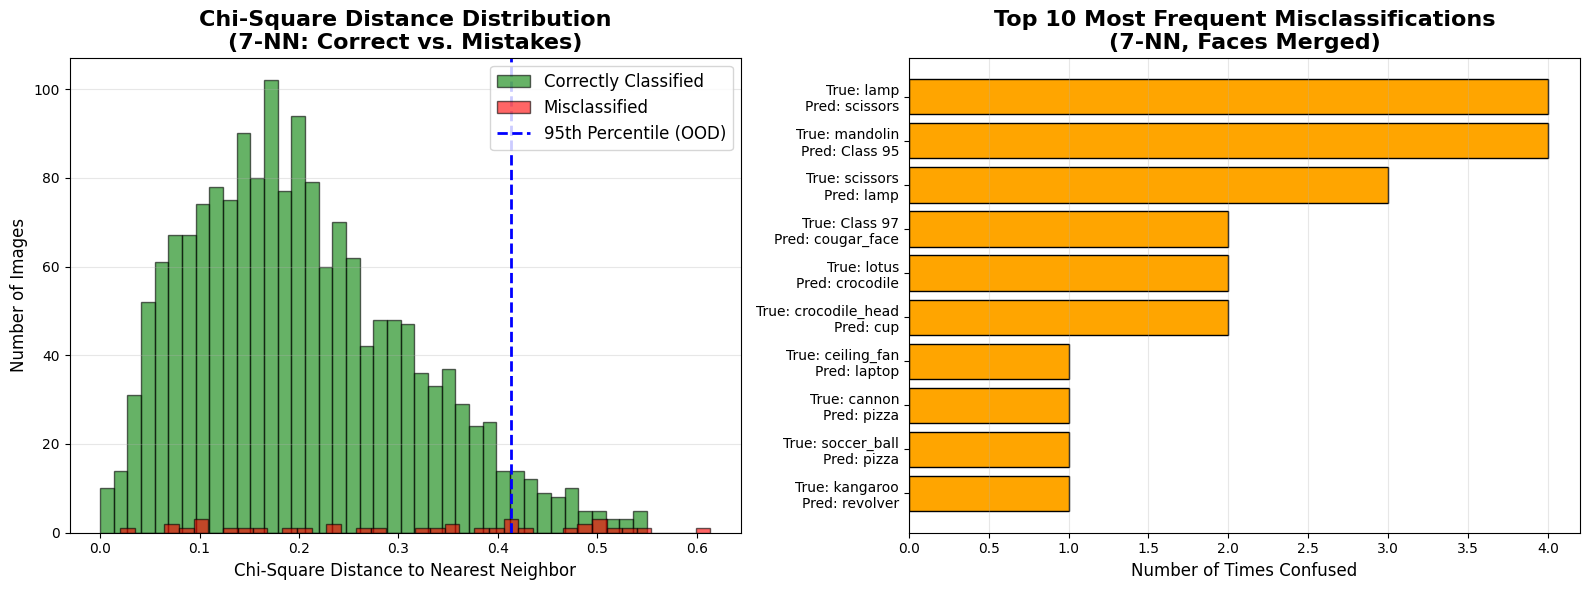

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.hist(correct_distances, bins=40, alpha=0.6, color='green', edgecolor='black', label='Correctly Classified')
if len(incorrect_distances) > 0:
    ax1.hist(incorrect_distances, bins=40, alpha=0.6, color='red', edgecolor='black', label='Misclassified')

ax1.axvline(np.percentile(all_distances, 95), color='blue', linestyle='dashed', linewidth=2, label='95th Percentile (OOD)')
ax1.set_title(f"Chi-Square Distance Distribution\n({K_NN}-NN: Correct vs. Mistakes)", fontsize=16, fontweight='bold')
ax1.set_xlabel("Chi-Square Distance to Nearest Neighbor", fontsize=12)
ax1.set_ylabel("Number of Images", fontsize=12)
ax1.legend(fontsize=12)
ax1.grid(axis='y', alpha=0.3)

if len(confusion_pairs) > 0:
    mistake_counts = Counter(confusion_pairs).most_common(10)

    def get_class_name(idx):
        if idx < len(class_names):
            return class_names[idx]
        return f"Class {idx}"

    pair_labels = [f"True: {get_class_name(true)}\nPred: {get_class_name(pred)}" for (true, pred), count in mistake_counts]
    counts = [count for (true, pred), count in mistake_counts]

    ax2.barh(pair_labels[::-1], counts[::-1], color='orange', edgecolor='black')
    ax2.set_title(f"Top 10 Most Frequent Misclassifications\n({K_NN}-NN, Faces Merged)", fontsize=16, fontweight='bold')
    ax2.set_xlabel("Number of Times Confused", fontsize=12)
    ax2.grid(axis='x', alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'No Mistakes Found!', ha='center', va='center', fontsize=20)
    ax2.axis('off')

plt.tight_layout()
plt.show()

## **5. OOD Experiments**

In [ ]:
import urllib.request
from PIL import Image
import io
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
import skimage.data

### **5.1 Data Download**

In [ ]:
ood_features = []
ood_names = []

In [ ]:
num_registers = getattr(model.config, "num_register_tokens", 4)
print(f"Skipping 1 CLS token + {num_registers} Register tokens...")

Skipping 1 CLS token + 4 Register tokens...


### **5.2 Evaluation**

In [ ]:
model.eval()
with torch.no_grad():
    for name, img in ood_images.items():
        if img is None:
            continue
        try:
            print(f"   -> Processing {name}...")

            # Pass through your DINOv3 pipeline
            pixel_values = transform(img).unsqueeze(0).to(model.device)
            outputs = model(pixel_values)
            last_hidden_state = outputs.last_hidden_state

            # Slice off CLS and Registers
            patch_tokens = last_hidden_state[0, 1 + num_registers:]

            ood_features.append(patch_tokens.cpu())
            ood_names.append(name)
            print(f"      ✅ Success!")

        except Exception as e:
            print(f"   ❌ Failed to process {name}: {e}")

   -> Processing Pikachu...
      ✅ Success!
   -> Processing Deep_Space...
      ✅ Success!
   -> Processing Medical_Cells...
      ✅ Success!
   -> Processing Text_Document...
      ✅ Success!
   -> Processing Human_Mitosis...
      ✅ Success!


In [ ]:
print(f"\n🎉 Successfully extracted patches for {len(ood_names)} OOD images!")


🎉 Successfully extracted patches for 5 OOD images!


# **Benchmarking**

## **1. Dataset**
We will need to seperate OOD datasets seperatly

In [42]:
import urllib.request
import io
from PIL import Image
import skimage.data
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
import matplotlib.patches as patches
from collections import Counter

In [28]:
ood_raw_data = {
    "DTD": [],
    "SVHN": [],
    "Pokemon": [],
    "Scientific": [],
    "Places365": []
}

In [30]:
dtd_dataset = torchvision.datasets.DTD(root='./data', split='test', download=True)
dtd_indices = np.random.choice(len(dtd_dataset), 1000, replace=False)
for idx in dtd_indices:
    img, _ = dtd_dataset[idx]
    ood_raw_data["DTD"].append(img.convert('RGB'))

In [31]:
svhn_dataset = torchvision.datasets.SVHN(root='./data', split='test', download=True)
svhn_indices = np.random.choice(len(svhn_dataset), 1000, replace=False)
for idx in svhn_indices:
    img, _ = svhn_dataset[idx]
    ood_raw_data["SVHN"].append(img.convert('RGB'))

In [32]:
try:
    places_dataset = torchvision.datasets.Places365(root='./data', split='val', small=True, download=True)
    places_indices = np.random.choice(len(places_dataset), 1000, replace=False)
    for idx in places_indices:
        img, _ = places_dataset[idx]
        ood_raw_data["Places365"].append(img.convert('RGB'))
except Exception as e:
    print(f"⚠️ Places365 download failed/skipped: {e}")


In [33]:
for i in range(1, 200):
    try:
        url = f"https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/{i}.png"
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as response:
            img = Image.open(io.BytesIO(response.read())).convert('RGB')
            ood_raw_data["Pokemon"].append(img)
    except Exception:
        pass

In [34]:
sk_images = [skimage.data.human_mitosis(), skimage.data.immunohistochemistry(),
             skimage.data.hubble_deep_field(), skimage.data.page(),
             skimage.data.retina(), skimage.data.cell(), skimage.data.coins(),
             skimage.data.moon(), skimage.data.gravel(), skimage.data.brick()]
for arr in sk_images:
    ood_raw_data["Scientific"].append(Image.fromarray(arr).convert('RGB'))

In [35]:
total_images = sum(len(imgs) for imgs in ood_raw_data.values())
print(f"✅ Gathered {total_images} raw images across {len(ood_raw_data)} datasets.")
print("🧠 Extracting DINOv3 features...")

✅ Gathered 6418 raw images across 5 datasets.
🧠 Extracting DINOv3 features...


### **1.1 OOD Features**

In [36]:
ood_features = {
    "DTD": [],
    "SVHN": [],
    "Pokemon": [],
    "Scientific": [],
    "Places365": []
}

In [37]:
num_registers = getattr(model.config, "num_register_tokens", 4)
model.eval()

with torch.no_grad():
    # Loop through our dictionary keys (the dataset names)
    for dataset_name, images_list in ood_raw_data.items():
        print(f"Extracting features for {dataset_name}...")

        for img in images_list:
            try:
                pixel_values = transform(img).unsqueeze(0).to(model.device)
                outputs = model(pixel_values)
                patch_tokens = outputs.last_hidden_state[0, 1 + num_registers:]

                # Append the features to the correct dataset list
                ood_features[dataset_name].append(patch_tokens.cpu())
            except Exception as e:
                pass # Silently skip corrupted images

print("🎉 Feature extraction complete! Ready for evaluation.")

Extracting features for DTD...
Extracting features for SVHN...
Extracting features for Pokemon...
Extracting features for Scientific...
Extracting features for Places365...
🎉 Feature extraction complete! Ready for evaluation.


### **1.2 Clustering and Histograms for the new dataset**

In [38]:
ood_hists_dict = {}

In [39]:
print("📊 Converting features to Bag-of-Visual-Words histograms...")

for dataset_name, feature_list in ood_features.items():
    print(f"Processing {dataset_name}...")

    feats_np = to_numpy_array(feature_list)

    dataset_hists = []

    for feats in feats_np:
        feats_f32 = feats.reshape(-1, d).astype(np.float32)
        _, I = index.search(feats_f32, 1)

        # 'k' is your vocabulary size / number of clusters
        hist = np.bincount(I.flatten(), minlength=k)
        dataset_hists.append(hist)

    # L1 Normalize the histograms for this dataset
    dataset_hists_np = np.array(dataset_hists)
    dataset_l1 = dataset_hists_np / (np.sum(dataset_hists_np, axis=1, keepdims=True) + 1e-10)

    # Save the normalized histograms back to our new dictionary!
    ood_hists_dict[dataset_name] = dataset_l1

print(f"🎉 FINAL SUCCESS! Successfully built normalized histograms for {len(ood_hists_dict)} OOD datasets!")

📊 Converting features to Bag-of-Visual-Words histograms...
Processing DTD...
Processing SVHN...
Processing Pokemon...
Processing Scientific...
Processing Places365...
🎉 FINAL SUCCESS! Successfully built normalized histograms for 5 OOD datasets!


## **2. Evaluation Loop**

In [40]:
FACES_GROUP = [class_names.index(f) for f in ['Faces', 'Faces_easy'] if f in class_names]
PRIMARY_FACE_ID = FACES_GROUP[0] if FACES_GROUP else -1

## **2.1 Model parameters**

In [44]:
K_NN = 7
DISTANCE_THRESHOLD = 0.5  # Rule 1: Distance must be > 0.5
CHAOS_THRESHOLD = 3 # Rule 2: Must have > CHAOS_THRESHOLD unique classes in the 7-NN neighborhood
OOD_LABEL = -1

In [43]:
benchmark_results = {}

### **2.3 Evaluation**


📊 EVALUATING: Caltech-101 (ID) vs DTD (OOD)

🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):
   -> Alien Catch Rate (Recall): 94.70% (1894/2000 caught)
   -> Missed Aliens (Slipped in): 106 images
   -> False Alarms (ID flagged):  8 images (0.46%)
🎯 IN-DISTRIBUTION (ID) PERFORMANCE:
   -> ID Accuracy (of those not flagged): 97.11% (1678/1728)
   -> Standard Test Error: 2.89%

🕵️ WHAT DID THE MISSED ALIENS SNEAK IN AS?
   -> Disguised as 'dollar_bill': 90 times
   -> Disguised as 'ant': 13 times
   -> Disguised as 'butterfly': 3 times


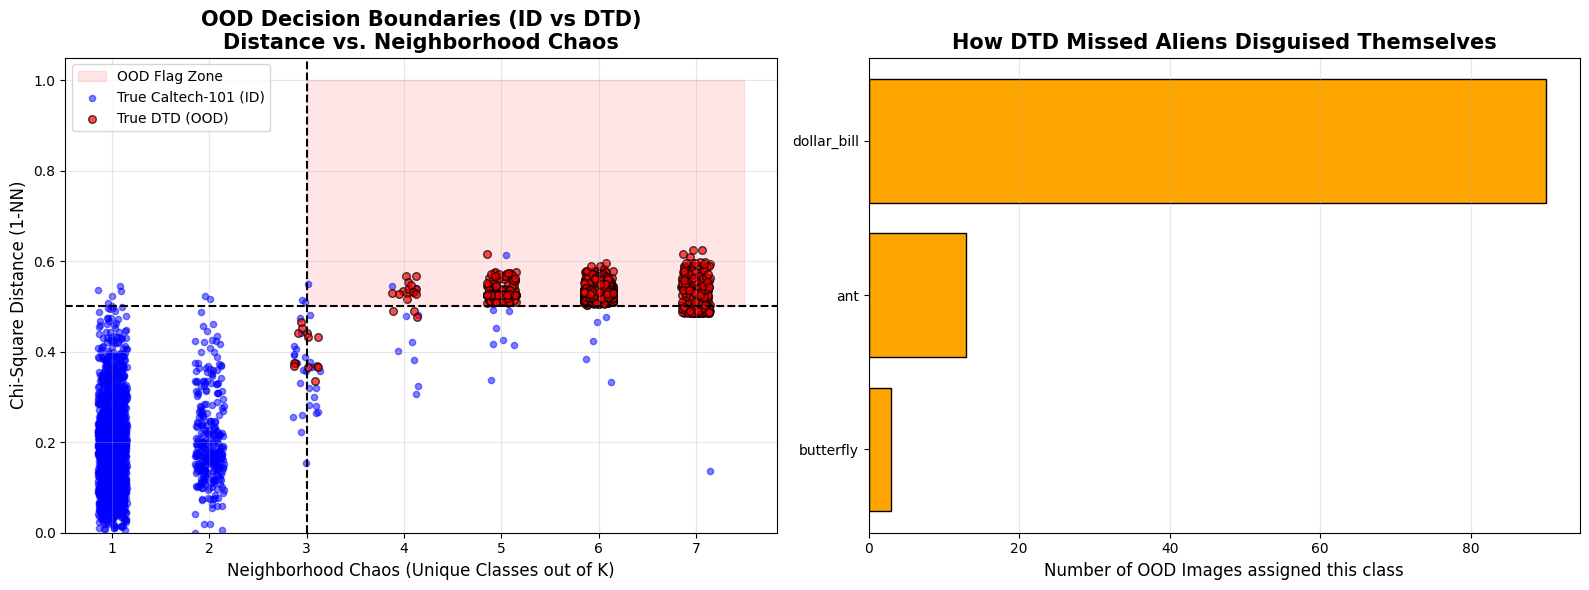


📊 EVALUATING: Caltech-101 (ID) vs SVHN (OOD)

🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):
   -> Alien Catch Rate (Recall): 99.55% (1991/2000 caught)
   -> Missed Aliens (Slipped in): 9 images
   -> False Alarms (ID flagged):  8 images (0.46%)
🎯 IN-DISTRIBUTION (ID) PERFORMANCE:
   -> ID Accuracy (of those not flagged): 97.11% (1678/1728)
   -> Standard Test Error: 2.89%

🕵️ WHAT DID THE MISSED ALIENS SNEAK IN AS?
   -> Disguised as 'dollar_bill': 9 times


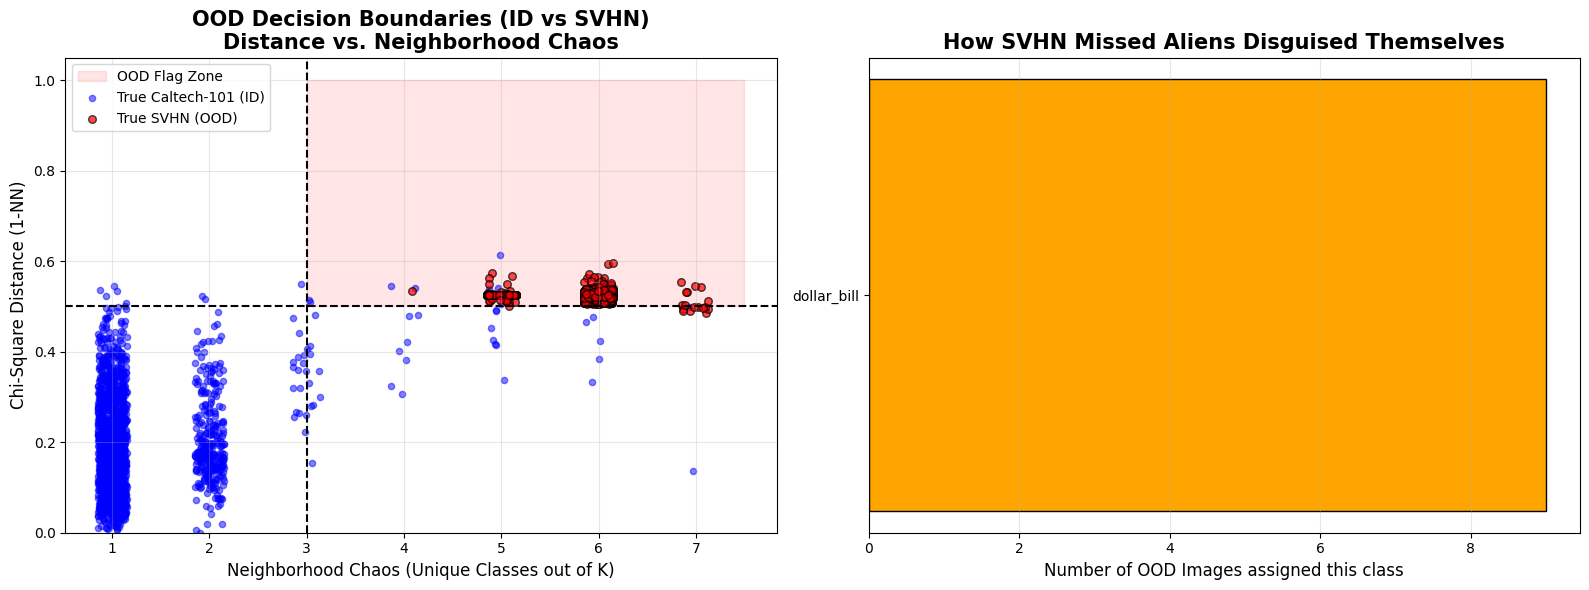


📊 EVALUATING: Caltech-101 (ID) vs Pokemon (OOD)

🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):
   -> Alien Catch Rate (Recall): 99.50% (396/398 caught)
   -> Missed Aliens (Slipped in): 2 images
   -> False Alarms (ID flagged):  8 images (0.46%)
🎯 IN-DISTRIBUTION (ID) PERFORMANCE:
   -> ID Accuracy (of those not flagged): 97.11% (1678/1728)
   -> Standard Test Error: 2.89%

🕵️ WHAT DID THE MISSED ALIENS SNEAK IN AS?
   -> Disguised as 'binocular': 2 times


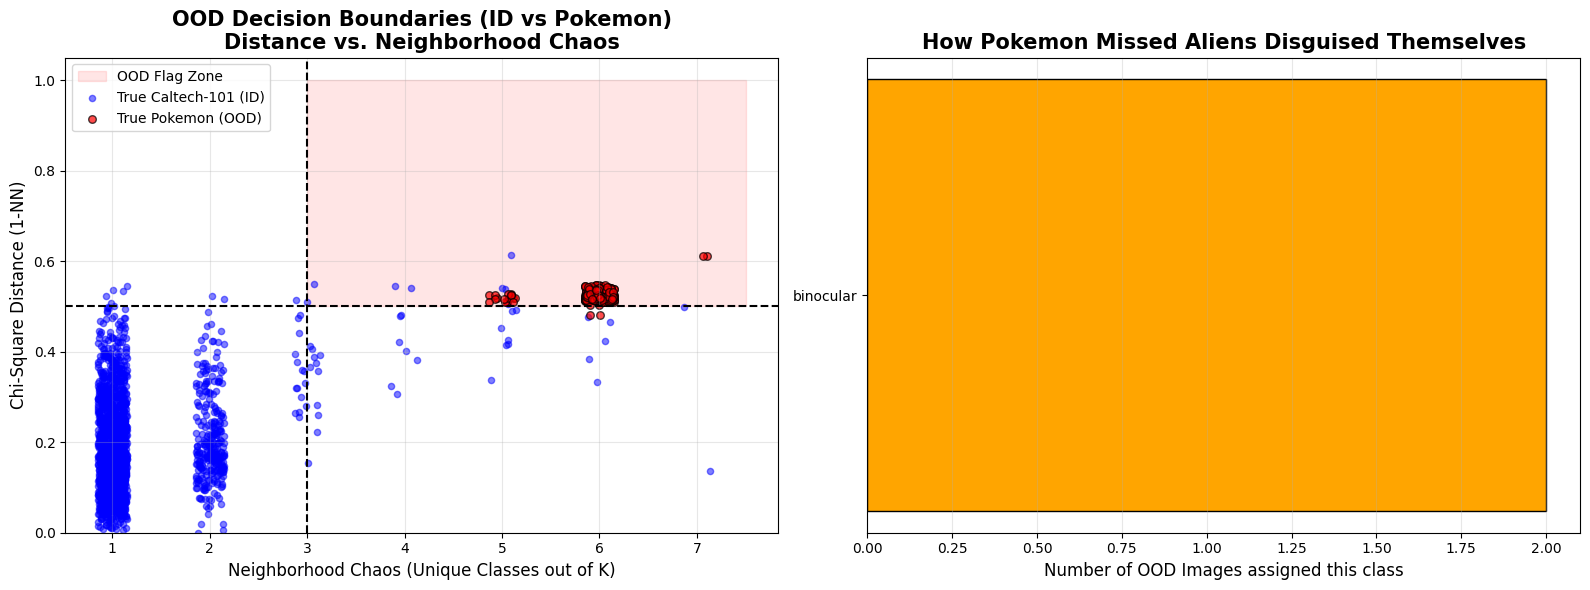


📊 EVALUATING: Caltech-101 (ID) vs Scientific (OOD)

🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):
   -> Alien Catch Rate (Recall): 100.00% (20/20 caught)
   -> Missed Aliens (Slipped in): 0 images
   -> False Alarms (ID flagged):  8 images (0.46%)
🎯 IN-DISTRIBUTION (ID) PERFORMANCE:
   -> ID Accuracy (of those not flagged): 97.11% (1678/1728)
   -> Standard Test Error: 2.89%


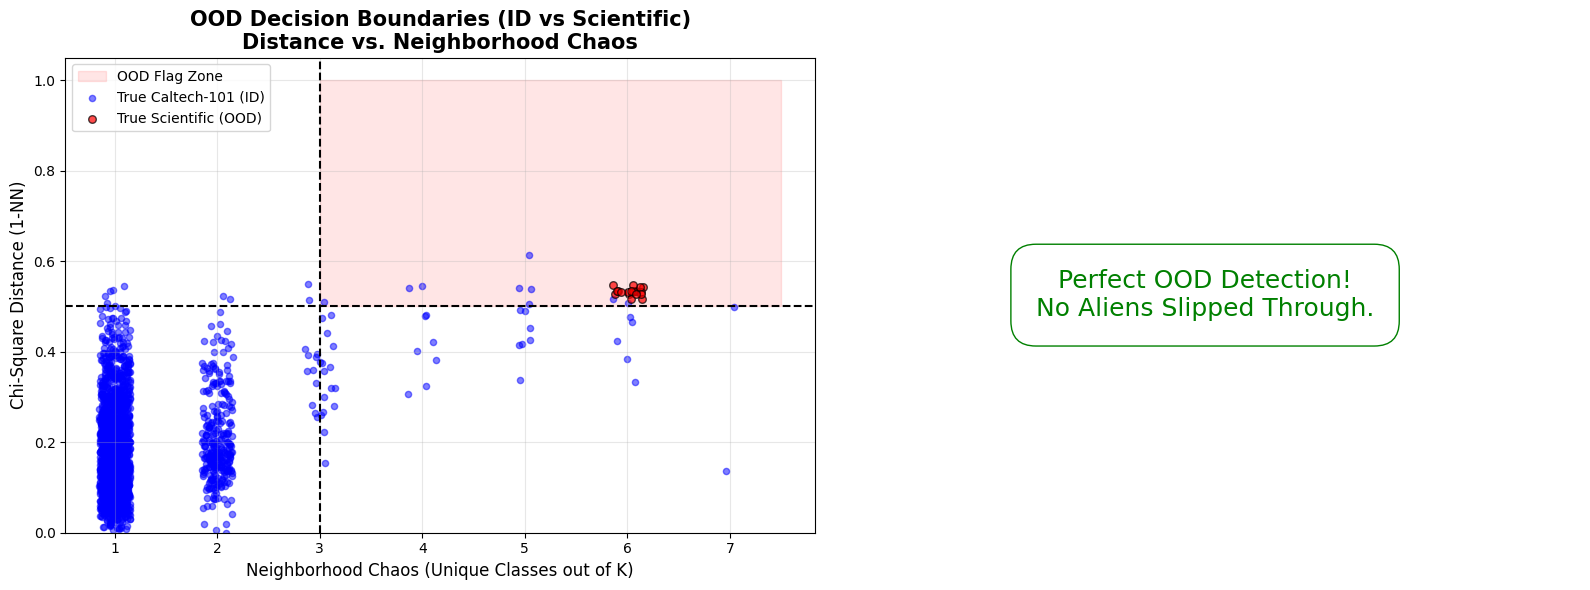


📊 EVALUATING: Caltech-101 (ID) vs Places365 (OOD)

🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):
   -> Alien Catch Rate (Recall): 98.65% (1973/2000 caught)
   -> Missed Aliens (Slipped in): 27 images
   -> False Alarms (ID flagged):  8 images (0.46%)
🎯 IN-DISTRIBUTION (ID) PERFORMANCE:
   -> ID Accuracy (of those not flagged): 97.11% (1678/1728)
   -> Standard Test Error: 2.89%

🕵️ WHAT DID THE MISSED ALIENS SNEAK IN AS?
   -> Disguised as 'dollar_bill': 21 times
   -> Disguised as 'binocular': 3 times
   -> Disguised as 'ant': 2 times


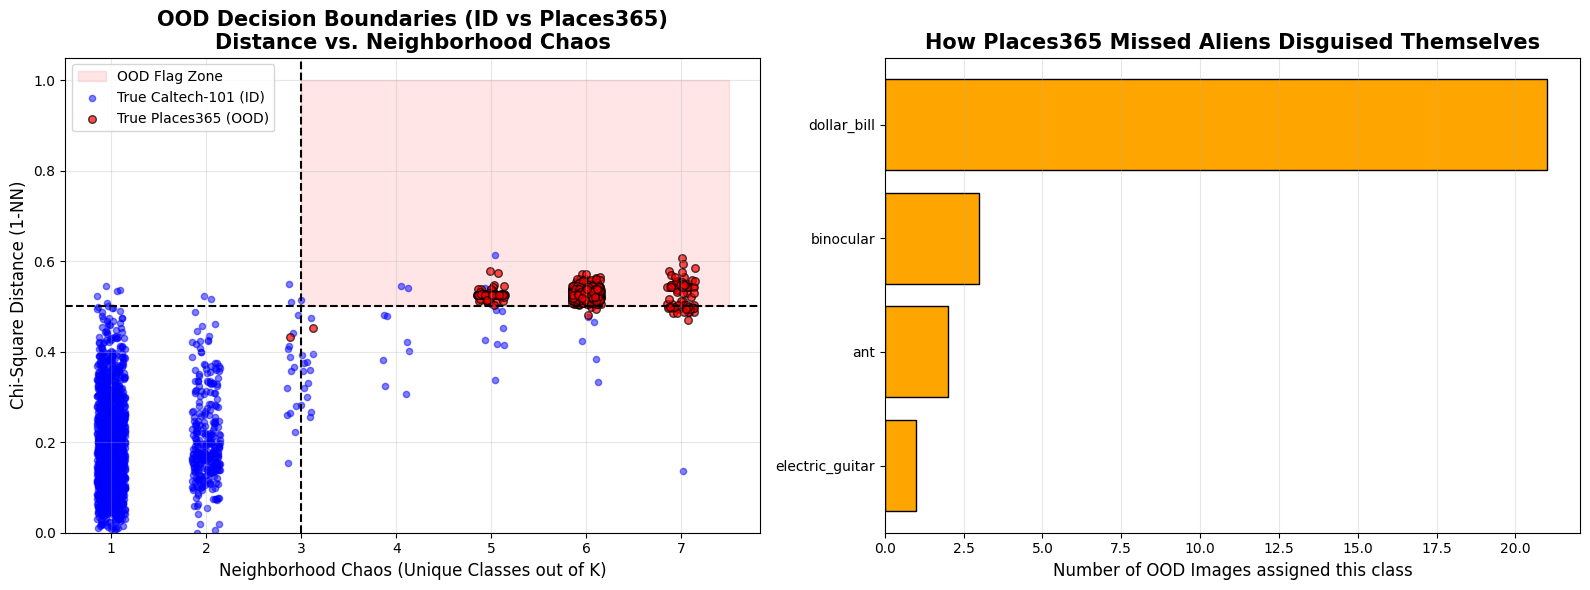

In [45]:
for ood_name, ood_l1 in ood_hists_dict.items():
    print(f"\n{'='*80}")
    print(f"📊 EVALUATING: Caltech-101 (ID) vs {ood_name} (OOD)")
    print(f"{'='*80}")

    # --- 1. SETUP DATA FOR THIS SPECIFIC OOD COMPARISON ---
    mixed_test_l1 = np.vstack((test_l1, ood_l1))

    # Labels for Hard Metrics
    ood_labels_hard = np.full(len(ood_l1), OOD_LABEL)
    mixed_y_test = np.concatenate((y_test, ood_labels_hard))

    # Tracking variables for Hard Metrics & Plotting
    correctly_flagged_ood, missed_ood, false_alarms_id = 0, 0, 0
    correct_id_classifications, incorrect_id_classifications = 0, 0
    missed_ood_assigned_classes = []
    plot_data = {"id_dist": [], "id_chaos": [], "ood_dist": [], "ood_chaos": []}

    # Tracking for Continuous Sklearn Metrics
    y_true_binary = [] # 0 for ID, 1 for OOD
    ood_continuous_scores = []

    # --- 2. RUN K-NN AND COLLECT STATS ---
    for t_idx in range(len(mixed_test_l1)):
        test_vec = mixed_test_l1[t_idx]
        true_label = int(mixed_y_test[t_idx])
        is_actually_ood = (true_label == OOD_LABEL)

        # Chi-Square Distance
        numerator = (train_l1 - test_vec) ** 2
        denominator = train_l1 + test_vec + 1e-10
        distances = 0.5 * np.sum(numerator / denominator, axis=1)

        nearest_indices = np.argsort(distances)[:K_NN]
        min_dist = distances[nearest_indices[0]]

        raw_nearest_labels = [int(y_train[idx]) for idx in nearest_indices]
        # (Assuming FACES_GROUP / PRIMARY_FACE_ID logic is handled or removed here)
        mapped_nearest_labels = raw_nearest_labels
        mapped_true_label = true_label

        unique_classes = len(set(mapped_nearest_labels))

        # Save continuous data for AUROC
        y_true_binary.append(1 if is_actually_ood else 0)
        ood_continuous_scores.append(min_dist) # Using min_dist as our "OOD Score"

        # Save plotting data
        if is_actually_ood:
            plot_data["ood_dist"].append(min_dist)
            plot_data["ood_chaos"].append(unique_classes)
        else:
            plot_data["id_dist"].append(min_dist)
            plot_data["id_chaos"].append(unique_classes)

        # Hard Threshold Prediction Logic
        if min_dist > DISTANCE_THRESHOLD and unique_classes > CHAOS_THRESHOLD:
            final_prediction = OOD_LABEL
        else:
            final_prediction = Counter(mapped_nearest_labels).most_common(1)[0][0]

        # Track Success/Failures
        if is_actually_ood:
            if final_prediction == OOD_LABEL:
                correctly_flagged_ood += 1
            else:
                missed_ood += 1
                missed_ood_assigned_classes.append(final_prediction)
        else:
            if final_prediction == OOD_LABEL:
                false_alarms_id += 1
            else:
                if final_prediction == mapped_true_label:
                    correct_id_classifications += 1
                else:
                    incorrect_id_classifications += 1

    # --- 3. CALCULATE CONTINUOUS METRICS (AUROC, etc) ---
    y_true_arr = np.array(y_true_binary)
    scores_arr = np.array(ood_continuous_scores)

    auroc = roc_auc_score(y_true_arr, scores_arr)
    aupr = average_precision_score(y_true_arr, scores_arr)

    fpr, tpr, thresholds = roc_curve(y_true_arr, scores_arr)
    idx95 = np.where(tpr >= 0.95)[0][0]
    fpr95 = fpr[idx95]

    # Save to master results table
    benchmark_results[ood_name] = {"AUROC": auroc, "AUPR": aupr, "FPR95": fpr95}

    # --- 4. PRINT HARD THRESHOLD STATS FOR THIS DATASET ---
    total_id = len(test_l1)
    total_ood = len(ood_l1)

    print("\n🛡️ OOD DETECTION PERFORMANCE (Based on Hard Thresholds):")
    print(f"   -> Alien Catch Rate (Recall): {(correctly_flagged_ood/total_ood)*100:.2f}% ({correctly_flagged_ood}/{total_ood} caught)")
    print(f"   -> Missed Aliens (Slipped in): {missed_ood} images")
    print(f"   -> False Alarms (ID flagged):  {false_alarms_id} images ({(false_alarms_id/total_id)*100:.2f}%)")

    print("🎯 IN-DISTRIBUTION (ID) PERFORMANCE:")
    id_passed = total_id - false_alarms_id
    if id_passed > 0:
        print(f"   -> ID Accuracy (of those not flagged): {(correct_id_classifications/id_passed)*100:.2f}% ({correct_id_classifications}/{id_passed})")
        print(f"   -> Standard Test Error: {100 - (correct_id_classifications/id_passed)*100:.2f}%")

    if missed_ood > 0:
        print("\n🕵️ WHAT DID THE MISSED ALIENS SNEAK IN AS?")
        top_missed = Counter(missed_ood_assigned_classes).most_common(3)
        for cls_id, count in top_missed:
            print(f"   -> Disguised as '{get_class_name(cls_id)}': {count} times")

    # --- 5. VISUALIZE 2D DECISION BOUNDARY & BAR CHART ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # Plot 1: Scatter
    rect = patches.Rectangle((CHAOS_THRESHOLD, DISTANCE_THRESHOLD),
                             K_NN - CHAOS_THRESHOLD + 0.5, 1.0 - DISTANCE_THRESHOLD, # Adjust height if needed
                             linewidth=1, edgecolor='red', facecolor='red', alpha=0.1, label='OOD Flag Zone')
    ax1.add_patch(rect)

    jitter_id = np.random.uniform(-0.15, 0.15, len(plot_data["id_chaos"]))
    jitter_ood = np.random.uniform(-0.15, 0.15, len(plot_data["ood_chaos"]))

    ax1.scatter(np.array(plot_data["id_chaos"]) + jitter_id, plot_data["id_dist"],
                color='blue', alpha=0.5, s=20, label='True Caltech-101 (ID)')
    ax1.scatter(np.array(plot_data["ood_chaos"]) + jitter_ood, plot_data["ood_dist"],
                color='red', alpha=0.7, s=30, edgecolors='black', label=f'True {ood_name} (OOD)')

    ax1.axhline(DISTANCE_THRESHOLD, color='black', linestyle='--')
    ax1.axvline(CHAOS_THRESHOLD, color='black', linestyle='--')

    ax1.set_title(f"OOD Decision Boundaries (ID vs {ood_name})\nDistance vs. Neighborhood Chaos", fontsize=15, fontweight='bold')
    ax1.set_xlabel("Neighborhood Chaos (Unique Classes out of K)", fontsize=12)
    ax1.set_ylabel("Chi-Square Distance (1-NN)", fontsize=12)
    ax1.set_ylim(bottom=0)
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Plot 2: Bar Chart
    if missed_ood > 0:
        top_missed = Counter(missed_ood_assigned_classes).most_common(10)
        labels = [get_class_name(cls_id) for cls_id, _ in top_missed]
        counts = [count for _, count in top_missed]

        ax2.barh(labels[::-1], counts[::-1], color='orange', edgecolor='black')
        ax2.set_title(f"How {ood_name} Missed Aliens Disguised Themselves", fontsize=15, fontweight='bold')
        ax2.set_xlabel("Number of OOD Images assigned this class", fontsize=12)
        ax2.grid(axis='x', alpha=0.3)
    else:
        # Added bounding box to text to make it cleaner
        ax2.text(0.5, 0.5, 'Perfect OOD Detection!\nNo Aliens Slipped Through.',
                 ha='center', va='center', fontsize=18, color='green',
                 bbox=dict(facecolor='white', edgecolor='green', boxstyle='round,pad=1'))
        ax2.axis('off')

    plt.tight_layout()
    plt.show()

### **2.4 Results**

In [46]:
print("\n" + "=" * 55)
print(f"{'OOD Dataset':<15} | {'AUROC ↑':<10} | {'AUPR ↑':<10} | {'FPR95 ↓':<10}")
print("-" * 55)


OOD Dataset     | AUROC ↑    | AUPR ↑     | FPR95 ↓   
-------------------------------------------------------


In [48]:
print("\n" + "=" * 55)
print(f"{'OOD Dataset':<15} | {'AUROC ↑':<10} | {'AUPR ↑':<10} | {'FPR95 ↓':<10}")
print("-" * 55)
avg_auroc, avg_aupr, avg_fpr = 0, 0, 0
for name, metrics in benchmark_results.items():
    avg_auroc += metrics['AUROC']
    avg_aupr += metrics['AUPR']
    avg_fpr += metrics['FPR95']
    print(f"{name:<15} | {metrics['AUROC']*100:>6.2f}%   | {metrics['AUPR']*100:>6.2f}%   | {metrics['FPR95']*100:>6.2f}%")

print("-" * 55)
n = len(benchmark_results)
print(f"{'AVERAGE':<15} | {avg_auroc/n*100:>6.2f}%   | {avg_aupr/n*100:>6.2f}%   | {avg_fpr/n*100:>6.2f}%")
print("=" * 55)


OOD Dataset     | AUROC ↑    | AUPR ↑     | FPR95 ↓   
-------------------------------------------------------
DTD             |  99.41%   |  98.80%   |   1.09%
SVHN            |  99.45%   |  98.33%   |   0.81%
Pokemon         |  99.40%   |  92.68%   |   0.81%
Scientific      |  99.54%   |  55.93%   |   0.69%
Places365       |  99.45%   |  98.50%   |   0.81%
-------------------------------------------------------
AVERAGE         |  99.45%   |  88.85%   |   0.84%


## **Energy Based Scoring**

In [50]:
from sklearn.linear_model import LogisticRegression
from scipy.special import logsumexp
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

## **1. Function Definitions**

In [53]:
def get_energy_score(logits, T=1.0):
    """
    Compute the energy score.
    Lower energy = In-Distribution (ID)
    Higher energy = Out-Of-Distribution (OOD)
    """
    return -T * logsumexp(logits / T, axis=1)

In [52]:
def pool_features(feature_list):
    return np.array([feats.mean(dim=0).numpy() for feats in feature_list])

## **2. Model Prep**

In [70]:
train_gap = pool_features(caltech_train_features)
test_gap = pool_features(caltech_test_features)

In [71]:
ood_gap_dict = {}
for name, feats in ood_features.items():
    ood_gap_dict[name] = pool_features(feats)

In [72]:
ood_sample_name = list(ood_gap_dict.keys())[0]
ood_dim = ood_gap_dict[ood_sample_name].shape[1]

In [73]:
if train_gap.shape[1] != ood_dim:
    print(f"✂️ Dimension mismatch detected! ID has {train_gap.shape[1]}, OOD has {ood_dim}.")
    print("🔪 Slicing ID features to match OOD...")
    train_gap = train_gap[:, -ood_dim:]
    test_gap = test_gap[:, -ood_dim:]

✂️ Dimension mismatch detected! ID has 4096, OOD has 1024.
🔪 Slicing ID features to match OOD...


### **2.1 Training**

In [74]:
print("🧠 Training Linear Classification Head on Pure DINOv3 Features...")
# We train on the raw DINOv3 averages, completely ignoring histograms
clf = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs')
clf.fit(train_gap, y_train)
print("✅ Classifier trained!")

🧠 Training Linear Classification Head on Pure DINOv3 Features...
✅ Classifier trained!


In [75]:
id_logits = clf.decision_function(test_gap)
id_energy_scores = get_energy_score(id_logits)

threshold_95 = np.percentile(id_energy_scores, 95)
misclassified_id_count = np.sum(id_energy_scores > threshold_95)
total_id_count = len(id_energy_scores)

print("\n" + "=" * 55)
print("🎯 PURE ENERGY BASELINE: CALTECH-101 (ID)")
print(f"Threshold value selected for 95% TPR: {threshold_95:.4f}")
print(f"False Rejection Rate: {(misclassified_id_count / total_id_count) * 100:.2f} %")
print("=" * 55)


🎯 PURE ENERGY BASELINE: CALTECH-101 (ID)
Threshold value selected for 95% TPR: -5.9211
False Rejection Rate: 5.01 %


### **2.2 OOD**

In [76]:
energy_results = {}

In [79]:
for ood_name, ood_gap in ood_gap_dict.items():

    ood_logits = clf.decision_function(ood_gap)
    ood_energy_scores = get_energy_score(ood_logits)

    detected_ood_count = np.sum(ood_energy_scores > threshold_95)
    total_ood_count = len(ood_energy_scores)
    detection_rate = (detected_ood_count / total_ood_count) * 100

    y_true_binary = np.concatenate((np.zeros(len(id_energy_scores)), np.ones(len(ood_energy_scores))))
    combined_scores = np.concatenate((id_energy_scores, ood_energy_scores))

    auroc = roc_auc_score(y_true_binary, combined_scores)
    aupr = average_precision_score(y_true_binary, combined_scores)
    fpr, tpr, thresholds = roc_curve(y_true_binary, combined_scores)
    idx95 = np.where(tpr >= 0.95)[0][0]
    fpr95 = fpr[idx95]

    energy_results[ood_name] = {"DetectionRate": detection_rate, "AUROC": auroc, "AUPR": aupr, "FPR95": fpr95}

In [80]:
# --- MASTER PURE ENERGY BENCHMARK TABLE ---
print("\n" + "=" * 78)
print(f"⚡ PURE RAW ENERGY-BASED SCORING RESULTS ⚡")
print("-" * 78)
print(f"{'OOD Dataset':<15} | {'Detection Rate':<15} | {'AUROC ↑':<10} | {'AUPR ↑':<10} | {'FPR95 ↓':<10}")
print("-" * 78)

avg_det, avg_auroc, avg_aupr, avg_fpr = 0, 0, 0, 0
for name, metrics in energy_results.items():
    avg_det += metrics['DetectionRate']
    avg_auroc += metrics['AUROC']
    avg_aupr += metrics['AUPR']
    avg_fpr += metrics['FPR95']
    print(f"{name:<15} | {metrics['DetectionRate']:>13.2f}% | {metrics['AUROC']*100:>6.2f}%   | {metrics['AUPR']*100:>6.2f}%   | {metrics['FPR95']*100:>6.2f}%")

print("-" * 78)
n = len(energy_results)
print(f"{'AVERAGE':<15} | {avg_det/n:>13.2f}% | {avg_auroc/n*100:>6.2f}%   | {avg_aupr/n*100:>6.2f}%   | {avg_fpr/n*100:>6.2f}%")
print("=" * 78)


⚡ PURE RAW ENERGY-BASED SCORING RESULTS ⚡
------------------------------------------------------------------------------
OOD Dataset     | Detection Rate  | AUROC ↑    | AUPR ↑     | FPR95 ↓   
------------------------------------------------------------------------------
DTD             |         86.95% |  96.98%   |  94.18%   |   7.43%
SVHN            |         78.85% |  96.02%   |  91.02%   |   7.26%
Pokemon         |        100.00% |  99.52%   |  94.19%   |   0.75%
Scientific      |         80.00% |  95.85%   |  12.20%   |   6.22%
Places365       |         92.10% |  98.00%   |  96.27%   |   6.45%
------------------------------------------------------------------------------
AVERAGE         |         87.58% |  97.27%   |  77.57%   |   5.62%


# **MSP**

## **1. Function definiton**

In [81]:
def get_msp_score(probs):
    """
    Computes the MSP score from Softmax probabilities.
    Higher score (1 - max_prob) = more likely to be Out-of-Distribution.
    """
    max_probs = np.max(probs, axis=1)
    return 1.0 - max_probs

##

## **2. Evaluation**

### **2.1 ID**

In [82]:
id_probs = clf.predict_proba(test_gap)
id_msp_scores = get_msp_score(id_probs)

In [83]:
# Get the threshold where 95% of ID data is kept (False Rejection = 5%)
threshold_msp = np.percentile(id_msp_scores, 95)
misclassified_id_count = np.sum(id_msp_scores > threshold_msp)
total_id_count = len(id_msp_scores)

In [84]:
print("\n" + "=" * 55)
print("🎯 MSP BASELINE: CALTECH-101 (ID)")
print(f"Threshold value selected for 95% TPR: {threshold_msp:.4f}")
print(f"False Rejection Rate: {(misclassified_id_count / total_id_count) * 100:.2f} %")
print("=" * 55)


🎯 MSP BASELINE: CALTECH-101 (ID)
Threshold value selected for 95% TPR: 0.4273
False Rejection Rate: 5.01 %


### **2.2 OOD**

In [85]:
msp_results = {}

In [86]:
for ood_name, ood_gap in ood_gap_dict.items():

    # Get probabilities and MSP scores
    ood_probs = clf.predict_proba(ood_gap)
    ood_msp_scores = get_msp_score(ood_probs)

    # Calculate Hard Threshold Stats
    detected_ood_count = np.sum(ood_msp_scores > threshold_msp)
    total_ood_count = len(ood_msp_scores)
    detection_rate = (detected_ood_count / total_ood_count) * 100

    # Calculate Continuous Metrics (AUROC, AUPR, FPR95)
    y_true_binary = np.concatenate((np.zeros(len(id_msp_scores)), np.ones(len(ood_msp_scores))))
    combined_scores = np.concatenate((id_msp_scores, ood_msp_scores))

    auroc = roc_auc_score(y_true_binary, combined_scores)
    aupr = average_precision_score(y_true_binary, combined_scores)

    fpr, tpr, thresholds = roc_curve(y_true_binary, combined_scores)
    idx95 = np.where(tpr >= 0.95)[0][0]
    fpr95 = fpr[idx95]

    msp_results[ood_name] = {
        "DetectionRate": detection_rate,
        "AUROC": auroc,
        "AUPR": aupr,
        "FPR95": fpr95
    }

In [87]:
# --- 3. MASTER MSP BENCHMARK TABLE ---
print("\n" + "=" * 78)
print(f"📉 MAXIMUM SOFTMAX PROBABILITY (MSP) RESULTS 📉")
print("-" * 78)
print(f"{'OOD Dataset':<15} | {'Detection Rate':<15} | {'AUROC ↑':<10} | {'AUPR ↑':<10} | {'FPR95 ↓':<10}")
print("-" * 78)

avg_det, avg_auroc, avg_aupr, avg_fpr = 0, 0, 0, 0
for name, metrics in msp_results.items():
    avg_det += metrics['DetectionRate']
    avg_auroc += metrics['AUROC']
    avg_aupr += metrics['AUPR']
    avg_fpr += metrics['FPR95']
    print(f"{name:<15} | {metrics['DetectionRate']:>13.2f}% | {metrics['AUROC']*100:>6.2f}%   | {metrics['AUPR']*100:>6.2f}%   | {metrics['FPR95']*100:>6.2f}%")

print("-" * 78)
n = len(msp_results)
print(f"{'AVERAGE':<15} | {avg_det/n:>13.2f}% | {avg_auroc/n*100:>6.2f}%   | {avg_aupr/n*100:>6.2f}%   | {avg_fpr/n*100:>6.2f}%")
print("=" * 78)


📉 MAXIMUM SOFTMAX PROBABILITY (MSP) RESULTS 📉
------------------------------------------------------------------------------
OOD Dataset     | Detection Rate  | AUROC ↑    | AUPR ↑     | FPR95 ↓   
------------------------------------------------------------------------------
DTD             |         97.15% |  99.08%   |  98.72%   |   2.02%
SVHN            |         98.80% |  99.29%   |  98.80%   |   1.79%
Pokemon         |        100.00% |  99.84%   |  98.94%   |   0.29%
Scientific      |        100.00% |  99.28%   |  46.79%   |   1.61%
Places365       |         96.15% |  99.01%   |  98.82%   |   4.21%
------------------------------------------------------------------------------
AVERAGE         |         98.42% |  99.30%   |  88.42%   |   1.98%


# **Deep Ensemble**

In [95]:
from sklearn.utils import resample

## **1. Function Definition**

In [93]:
def get_ensemble_entropy(features, models):
    """
    Calculates the predictive entropy of the mean predictions from the ensemble.
    Higher entropy = more disagreement = Out-of-Distribution.
    """
    all_probs = []

    # Get softmax probabilities from every model
    for model in models:
        probs = model.predict_proba(features)
        all_probs.append(probs)

    # Stack them: Shape becomes (num_models, num_samples, num_classes)
    all_probs_stacked = np.stack(all_probs)

    # Average the probabilities across all models (mean predictions)
    mean_probs = np.mean(all_probs_stacked, axis=0)

    # Calculate Shannon Entropy: -sum(p * log(p))
    epsilon = 1e-10 # Prevent log(0)
    entropy = -np.sum(mean_probs * np.log(mean_probs + epsilon), axis=1)

    return entropy

## **2. Training**

In [88]:
NUM_ENSEMBLE_MODELS = 5

In [89]:
ensemble_models = []

In [92]:
for i in range(NUM_ENSEMBLE_MODELS):
    print(f"   -> Training Member {i+1}/{NUM_ENSEMBLE_MODELS} (using bootstrapped data)...")

    # Bootstrap: Randomly sample 80% of the training data for this specific model
    # This ensures each model learns slightly different decision boundaries!
    X_resampled, y_resampled = resample(train_gap, y_train, n_samples=int(len(train_gap)*0.8), random_state=i)

    model = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs')
    model.fit(X_resampled, y_resampled)
    ensemble_models.append(model)

print("✅ Ensemble training complete!\n")

   -> Training Member 1/5 (using bootstrapped data)...
   -> Training Member 2/5 (using bootstrapped data)...
   -> Training Member 3/5 (using bootstrapped data)...
   -> Training Member 4/5 (using bootstrapped data)...
   -> Training Member 5/5 (using bootstrapped data)...
✅ Ensemble training complete!



In [94]:
id_entropy_scores = get_ensemble_entropy(test_gap, ensemble_models)

threshold_ensemble = np.percentile(id_entropy_scores, 95)
misclassified_id_count = np.sum(id_entropy_scores > threshold_ensemble)
total_id_count = len(id_entropy_scores)

print("\n" + "=" * 55)
print("🎯 DEEP ENSEMBLE BASELINE: CALTECH-101 (ID)")
print(f"Threshold value selected for 95% TPR: {threshold_ensemble:.4f}")
print(f"False Rejection Rate: {(misclassified_id_count / total_id_count) * 100:.2f} %")
print("=" * 55)


🎯 DEEP ENSEMBLE BASELINE: CALTECH-101 (ID)
Threshold value selected for 95% TPR: 2.6555
False Rejection Rate: 5.01 %


## **3. Training**

In [96]:
ensemble_results = {}

In [97]:
for ood_name, ood_gap in ood_gap_dict.items():

    ood_entropy_scores = get_ensemble_entropy(ood_gap, ensemble_models)

    detected_ood_count = np.sum(ood_entropy_scores > threshold_ensemble)
    total_ood_count = len(ood_entropy_scores)
    detection_rate = (detected_ood_count / total_ood_count) * 100

    y_true_binary = np.concatenate((np.zeros(len(id_entropy_scores)), np.ones(len(ood_entropy_scores))))
    combined_scores = np.concatenate((id_entropy_scores, ood_entropy_scores))

    auroc = roc_auc_score(y_true_binary, combined_scores)
    aupr = average_precision_score(y_true_binary, combined_scores)

    fpr, tpr, thresholds = roc_curve(y_true_binary, combined_scores)
    idx95 = np.where(tpr >= 0.95)[0][0]
    fpr95 = fpr[idx95]

    ensemble_results[ood_name] = {
        "DetectionRate": detection_rate,
        "AUROC": auroc,
        "AUPR": aupr,
        "FPR95": fpr95
    }


In [98]:
print("\n" + "=" * 78)
print(f"🎲 DEEP ENSEMBLE (PREDICTIVE ENTROPY) RESULTS 🎲")
print("-" * 78)
print(f"{'OOD Dataset':<15} | {'Detection Rate':<15} | {'AUROC ↑':<10} | {'AUPR ↑':<10} | {'FPR95 ↓':<10}")
print("-" * 78)

avg_det, avg_auroc, avg_aupr, avg_fpr = 0, 0, 0, 0
for name, metrics in ensemble_results.items():
    avg_det += metrics['DetectionRate']
    avg_auroc += metrics['AUROC']
    avg_aupr += metrics['AUPR']
    avg_fpr += metrics['FPR95']
    print(f"{name:<15} | {metrics['DetectionRate']:>13.2f}% | {metrics['AUROC']*100:>6.2f}%   | {metrics['AUPR']*100:>6.2f}%   | {metrics['FPR95']*100:>6.2f}%")

print("-" * 78)
n = len(ensemble_results)
print(f"{'AVERAGE':<15} | {avg_det/n:>13.2f}% | {avg_auroc/n*100:>6.2f}%   | {avg_aupr/n*100:>6.2f}%   | {avg_fpr/n*100:>6.2f}%")
print("=" * 78)


🎲 DEEP ENSEMBLE (PREDICTIVE ENTROPY) RESULTS 🎲
------------------------------------------------------------------------------
OOD Dataset     | Detection Rate  | AUROC ↑    | AUPR ↑     | FPR95 ↓   
------------------------------------------------------------------------------
DTD             |         96.60% |  98.48%   |  96.82%   |   3.80%
SVHN            |         96.45% |  98.24%   |  95.89%   |   4.55%
Pokemon         |        100.00% |  99.76%   |  97.95%   |   0.46%
Scientific      |        100.00% |  98.53%   |  28.04%   |   2.48%
Places365       |         93.75% |  98.39%   |  97.49%   |   5.76%
------------------------------------------------------------------------------
AVERAGE         |         97.36% |  98.68%   |  83.24%   |   3.41%
